# DSC PJATK Catalogue Quality Challenge
EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

train = pd.read_csv('/kaggle/input/competitions/dsc-pjatk-catalogue-quality-challenge/train.csv')
print('Shape:', train.shape)
print('Target rate:', train['target'].mean().round(4))

Shape: (16000, 11)
Target rate: 0.1701


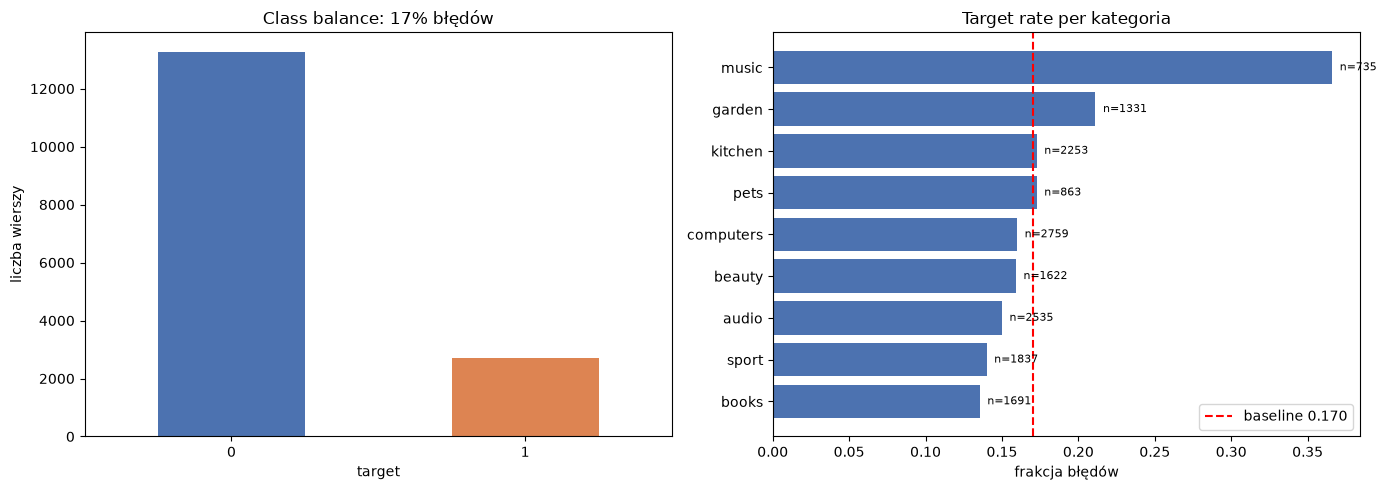

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train['target'].value_counts().plot.bar(ax=axes[0], color=['#4C72B0', '#DD8452'])
axes[0].set_title('Class balance: 17% błędów')
axes[0].set_xlabel('target')
axes[0].set_ylabel('liczba wierszy')
axes[0].tick_params(axis='x', rotation=0)

rate = train.groupby('declared_category')['target'].agg(['mean', 'size']).sort_values('mean')
axes[1].barh(rate.index, rate['mean'], color='#4C72B0')
axes[1].axvline(train['target'].mean(), color='red', linestyle='--',
                label=f'baseline {train["target"].mean():.3f}')
axes[1].set_title('Target rate per kategoria')
axes[1].set_xlabel('frakcja błędów')
for i, (idx, row) in enumerate(rate.iterrows()):
    axes[1].text(row['mean'] + 0.005, i, f'n={int(row["size"])}', va='center', fontsize=8)
axes[1].legend()

plt.tight_layout()
plt.show()

**Wnioski:**
- Class imbalance: tylko 17% listingów ma błąd — model musi obsługiwać niezbalansowane klasy.
- Błędy nie są równomierne: kategoria `music` ma 36.6% błędów, `sport` tylko 14%. To 2.6× różnica.
- `declared_category` jest silnym predyktorem — model powinien uczyć się interakcji kategoria × wzorzec błędu.

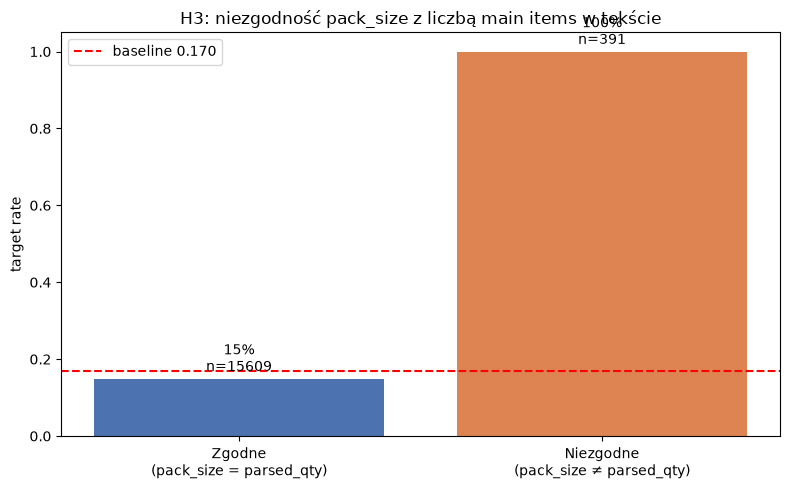

In [3]:
WORD2NUM = {'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5, 'six': 6, 'seven': 7,
            'eight': 8, 'nine': 9, 'ten': 10, 'zero': 0, 'single': 1}
NUMW = 'one|two|three|four|five|six|seven|eight|nine|ten'

def extract_qty(text):
    """Same main-item parser as the model (02_model.ipynb, qty_main_items)."""
    t = re.sub(r'\s+', ' ', str(text).lower())
    t = re.sub(r'also includes \d+ pcs? of free accessory[^.]*\.?', ' ', t)
    t = re.sub(r'free accessory[^.]*\.?', ' ', t)
    pats = [r'included main items:\s*(\d+)',
            r'(\d+)\s+individually boxed main items', rf'({NUMW})\s+individually boxed main items',
            r'(\d+)\s+main items', rf'({NUMW})\s+main items',
            rf'pack of ({NUMW}) main items', r'pack of (\d+) main items',
            r'bundle quantity:\s*(\d+)', r'(\d+)\s*-?pack', r'sold as a (\d+)-pack',
            r'\(quantity\s*(\d+)\)', r'quantity\s*(\d+)', r'(\d+)\s*units',
            r'package contains\s*(\d+)', r'(\d+)\s*pcs', rf'pack of ({NUMW})']
    for p in pats:
        m = re.search(p, t)
        if m:
            v = m.group(1)
            return WORD2NUM.get(v) if v.isalpha() else int(v)
    return None

train['parsed_qty'] = train.apply(
    lambda r: extract_qty(('' if pd.isna(r['title']) else r['title']) + ' ' + ('' if pd.isna(r['description']) else r['description'])), axis=1)

train['qty_vs_pack'] = (train['parsed_qty'].notna() &
                         train['pack_size'].notna() &
                         (train['parsed_qty'] != train['pack_size']))

fig, ax = plt.subplots(figsize=(8, 5))
grp = train.groupby('qty_vs_pack')['target'].agg(['mean', 'size', 'sum'])
bars = ax.bar(['Zgodne\n(pack_size = parsed_qty)', 'Niezgodne\n(pack_size ≠ parsed_qty)'],
              grp['mean'], color=['#4C72B0', '#DD8452'])
ax.set_ylabel('target rate')
ax.set_title('H3: niezgodność pack_size z liczbą main items w tekście')
ax.axhline(train['target'].mean(), color='red', linestyle='--', label='baseline 0.170')
for bar, (idx, row) in zip(bars, grp.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f"{row['mean']:.0%}\nn={int(row['size'])}", ha='center', fontsize=10)
ax.legend()
plt.tight_layout()
plt.show()

**Wnioski:**
- Gdy `pack_size` zgadza się z liczbą main items w tekście → target rate 14.9% (baseline).
- Gdy się NIE zgadza → **target rate 100%** na 391 wierszach.
- To sygnał **deterministyczny**, nie statystyczny. Reguła: "jeśli pack_size ≠ liczba main items w tekście, to błąd".
- Sygnał wykorzystany w modelu jako feature `mvp_mismatch`.

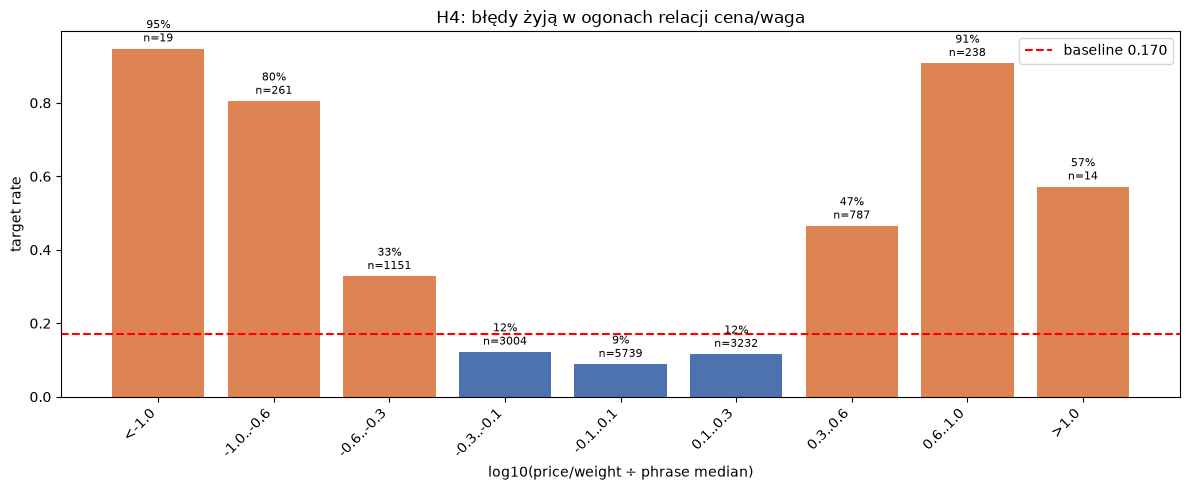

In [4]:
def get_phrase(desc):
    m = re.search(r'([a-z][a-z\s\-/]{2,40}?)\s+by\s+(?:mira|noro|velto|tenso|aster)',
                  str(desc).lower())
    return m.group(1).strip() if m else ''

train['phrase'] = train['description'].fillna('').str.lower().apply(get_phrase)
train['pw'] = train['price_pln'] / train['shipping_weight_kg'].clip(lower=1e-6)
train['pw_median'] = train.groupby('phrase')['pw'].transform('median')
train['logr'] = np.log10((train['pw'] / train['pw_median'].clip(lower=1e-9)).clip(lower=1e-9))

bins = [-np.inf, -1.0, -0.6, -0.3, -0.1, 0.1, 0.3, 0.6, 1.0, np.inf]
labels = ['<-1.0', '-1.0..-0.6', '-0.6..-0.3', '-0.3..-0.1', '-0.1..0.1',
          '0.1..0.3', '0.3..0.6', '0.6..1.0', '>1.0']
train['bin'] = pd.cut(train['logr'], bins=bins, labels=labels)
grp = train.groupby('bin', observed=True)['target'].agg(['mean', 'size', 'sum'])

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#DD8452' if m > 0.3 else '#4C72B0' for m in grp['mean']]
bars = ax.bar(range(len(grp)), grp['mean'], color=colors)
ax.set_xticks(range(len(grp)))
ax.set_xticklabels(grp.index, rotation=45, ha='right')
ax.set_ylabel('target rate')
ax.set_xlabel('log10(price/weight ÷ phrase median)')
ax.set_title('H4: błędy żyją w ogonach relacji cena/waga')
ax.axhline(train['target'].mean(), color='red', linestyle='--', label='baseline 0.170')
for bar, (idx, row) in zip(bars, grp.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f"{row['mean']:.0%}\nn={int(row['size'])}", ha='center', fontsize=8)
ax.legend()
plt.tight_layout()
plt.show()

**Wnioski:**
- W środku rozkładu (−0.1 do 0.1) target rate wynosi 8.8%, poniżej średniej 17%.
- W ogonach |log10| > 0.6 target rate wynosi **85%** (532 wiersze): dolny ogon (−1.0 do −0.6) 80.5%, górny (0.6 do 1.0) 90.8%. Oba ogony są sygnałem.
- Wniosek: błąd to **niespójność ceny i wagi względem typowej wartości dla tego samego produktu**, a nie po prostu nietypowa wartość.
- Uwaga: mediana frazy jest tu liczona na całym zbiorze treningowym, bo to opis danych, nie cecha. W modelu ten pomysł realizuje grupa `anomaly`: odporne z-score ceny i wagi na sztukę względem mediany frazy, liczone tylko na foldzie treningowym.

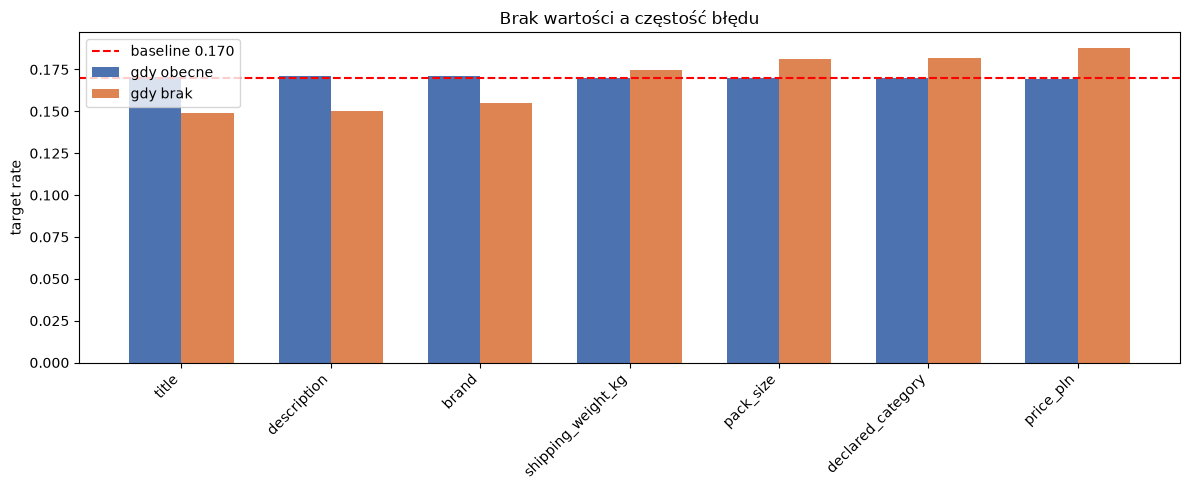

In [5]:
miss_cols = [c for c in ['title', 'description', 'brand', 'declared_category',
                         'price_pln', 'shipping_weight_kg', 'pack_size']
             if train[c].isna().mean() >= 0.01]

rows = []
for c in miss_cols:
    mask = train[c].isna()
    rows.append({'col': c,
                 'missing_frac': mask.mean(),
                 'target_rate_when_missing': train.loc[mask, 'target'].mean(),
                 'target_rate_when_present': train.loc[~mask, 'target'].mean(),
                 'n_missing': int(mask.sum())})
miss_df = pd.DataFrame(rows).sort_values('target_rate_when_missing')

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(miss_df))
w = 0.35
ax.bar(x - w/2, miss_df['target_rate_when_present'], w, label='gdy obecne', color='#4C72B0')
ax.bar(x + w/2, miss_df['target_rate_when_missing'], w, label='gdy brak', color='#DD8452')
ax.set_xticks(x)
ax.set_xticklabels(miss_df['col'], rotation=45, ha='right')
ax.set_ylabel('target rate')
ax.set_title('Brak wartości a częstość błędu')
ax.axhline(train['target'].mean(), color='red', linestyle='--', label='baseline 0.170')
ax.legend()
plt.tight_layout()
plt.show()

**Wnioski:**
- Odsetek błędów przy brakach mieści się w okolicy średniej 17%: przy braku `title` 14.9%, `description` 15.0%, `brand` 15.5%, `shipping_weight_kg` 17.5%, `pack_size` 18.1%, `declared_category` 18.2%, `price_pln` 18.8%.
- Przy grupach liczących od 370 do 960 wierszy takie różnice mieszczą się w szumie losowym. Brak wartości sam w sobie nie oznacza błędu, co zgadza się z opisem organizatorów.
- Flagi `isna_*` zostają w modelu, ale niosą mało sygnału. Brak ma znaczenie głównie dlatego, że wyłącza któryś z testów spójności (np. brak `pack_size` uniemożliwia policzenie ceny na sztukę).

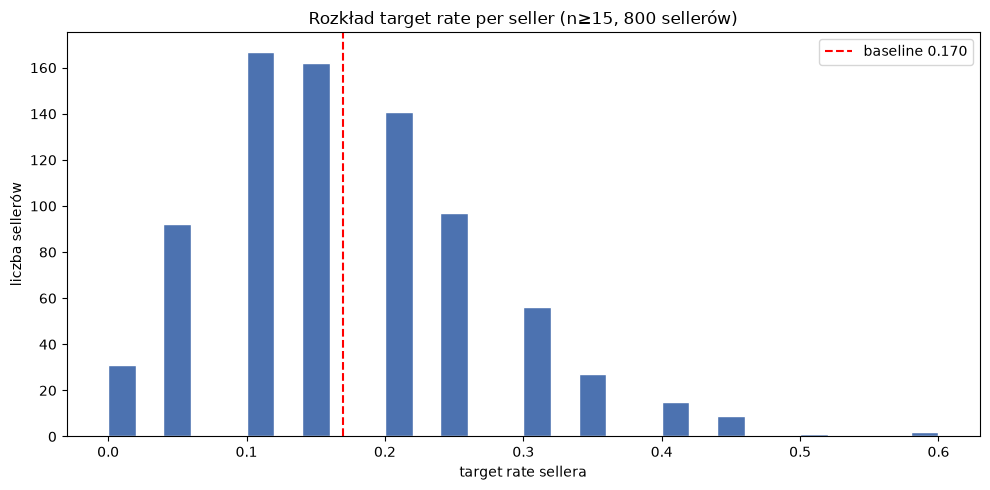

count    800.000
mean       0.170
std        0.098
min        0.000
25%        0.100
50%        0.150
75%        0.250
max        0.600
Name: mean, dtype: float64


In [6]:
seller_stats = train.groupby('seller_id')['target'].agg(['mean', 'size'])
seller_stats = seller_stats[seller_stats['size'] >= 15]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(seller_stats['mean'], bins=30, color='#4C72B0', edgecolor='white')
ax.axvline(train['target'].mean(), color='red', linestyle='--',
           label=f'baseline {train["target"].mean():.3f}')
ax.set_xlabel('target rate sellera')
ax.set_ylabel('liczba sellerów')
ax.set_title(f'Rozkład target rate per seller (n≥15, {len(seller_stats)} sellerów)')
ax.legend()
plt.tight_layout()
plt.show()
print(seller_stats['mean'].describe().round(3))

**Wnioski:**
- Odsetek błędów per seller waha się od 0% do 60%, ale przy 20 ofertach na sellera sam przypadek daje odchylenie standardowe 0.080 do 0.088 (symulacja dwumianowa), a obserwowane wynosi 0.098.
- Większość rozrzutu między sellerami to szum losowy, więc nie budujemy cech opartych na odsetku błędów sellera.
- Sellerzy mają jednak wspólny styl opisów i cen, a w teście są sami nowi sellerzy, dlatego walidacja jest seller-disjoint (foldy organizatorów, SHA-256 `seller_id`).
- Model nie używa `seller_id` jako cechy.

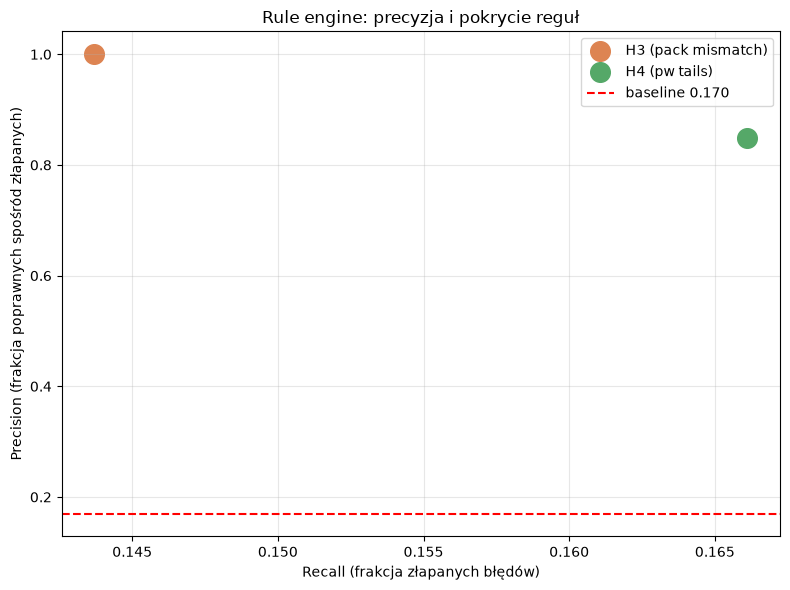

H3: precision=1.000, recall=0.144
H4: precision=0.850, recall=0.166


In [7]:
# H3 rule: pack_size != parsed_qty
h3_fire = train['qty_vs_pack']
h3_precision = train.loc[h3_fire, 'target'].mean()
h3_recall = train.loc[h3_fire, 'target'].sum() / train['target'].sum()

# H4 rule: |log10(pw_ratio)| > 0.6
h4_fire = train['logr'].abs() > 0.6
h4_precision = train.loc[h4_fire, 'target'].mean()
h4_recall = train.loc[h4_fire, 'target'].sum() / train['target'].sum()

# baseline
baseline_rate = train['target'].mean()

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(h3_recall, h3_precision, s=200, color='#DD8452', label='H3 (pack mismatch)')
ax.scatter(h4_recall, h4_precision, s=200, color='#55A868', label='H4 (pw tails)')
ax.axhline(baseline_rate, color='red', linestyle='--', label=f'baseline {baseline_rate:.3f}')
ax.set_xlabel('Recall (frakcja złapanych błędów)')
ax.set_ylabel('Precision (frakcja poprawnych spośród złapanych)')
ax.set_title('Rule engine: precyzja i pokrycie reguł')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'H3: precision={h3_precision:.3f}, recall={h3_recall:.3f}')
print(f'H4: precision={h4_precision:.3f}, recall={h4_recall:.3f}')

**Wnioski:**
- H3 (niezgodność `pack_size` z liczbą main items w tekście) ma precision 1.00 i recall 14.4%: reguła nigdy się nie myli w treningu, ale łapie mały wycinek błędów.
- H4 (ogony cena/waga względem mediany frazy) ma precision 0.85 i recall 16.6%.
- Reguły pokrywają różne części błędów, więc się uzupełniają, a większość błędów (zmiany kategorii i mniejsze zmiany ceny lub wagi) wymaga dalszych cech.
- W modelu: H3 to cecha `mvp_mismatch`, H4 realizuje grupa `anomaly` (`*_z_pp2`, `*_z_pc`, `*_hi_pp2`, `*_extreme_*`), a LightGBM uczy się łączyć je z pozostałymi sygnałami.